In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

here = Path.cwd()
ROOT = next(p for p in [here, *here.parents] if (p / "data" / "raw" / "sales.csv").exists())
df = pd.read_csv(ROOT / "data" / "raw" / "sales.csv", parse_dates=["date"])

In [2]:
TEST_START = pd.Timestamp("2025-10-01")

train = df[df["date"] < TEST_START]
test = df[df["date"] >= TEST_START].copy()

print(f"Train: {train['date'].min().date()} to {train['date'].max().date()}  ({len(train):,} rows)")
print(f"Test:  {test['date'].min().date()} to {test['date'].max().date()}  ({len(test):,} rows)")

Train: 2023-01-01 to 2025-09-30  (10,040 rows)
Test:  2025-10-01 to 2025-12-31  (920 rows)


In [3]:
def wape(actual, forecast):
    """Weighted absolute percentage error: total miss divided by total actual sales."""
    return np.abs(actual - forecast).sum() / actual.sum() * 100

def bias(actual, forecast):
    """Positive = over-forecasting (excess stock). Negative = under-forecasting (stockouts)."""
    return (forecast.sum() - actual.sum()) / actual.sum() * 100

In [4]:
# 1. Naive: "tomorrow will be like the last day we saw"
last_value = train.groupby("sku")["units_sold"].last()
test["naive"] = test["sku"].map(last_value)

# 2. Moving average: "the average of the last 4 weeks"
recent = train[train["date"] >= TEST_START - pd.Timedelta(days=28)]
test["moving_avg_28"] = test["sku"].map(recent.groupby("sku")["units_sold"].mean())

# 3. Seasonal naive: "same weekday as the last week we saw"
last_week = train[train["date"] >= TEST_START - pd.Timedelta(days=7)]
by_weekday = last_week.set_index([last_week["date"].dt.day_of_week, "sku"])["units_sold"]
test["seasonal_naive_7"] = [by_weekday[(d.day_of_week, s)] for d, s in zip(test["date"], test["sku"])]

# 4. Last year: "same day, 52 weeks ago" (364 days keeps the same weekday)
history = df.set_index(["date", "sku"])["units_sold"]
test["same_day_last_year"] = [history[(d - pd.Timedelta(days=364), s)] for d, s in zip(test["date"], test["sku"])]

test.head()

,date,sku,category,units_sold,on_promo,unit_price,naive,moving_avg_28,seasonal_naive_7,same_day_last_year
1004,2025-10-01,SKU-001,Beverages,202,0,2.49,141,181.464286,255,105
1005,2025-10-02,SKU-001,Beverages,132,0,2.49,141,181.464286,137,103
1006,2025-10-03,SKU-001,Beverages,127,0,2.49,141,181.464286,251,153
1007,2025-10-04,SKU-001,Beverages,174,0,2.49,141,181.464286,163,140
1008,2025-10-05,SKU-001,Beverages,151,0,2.49,141,181.464286,140,107


In [5]:
baselines = ["naive", "moving_avg_28", "seasonal_naive_7", "same_day_last_year"]
scores = pd.DataFrame({
    "WAPE_%": [wape(test["units_sold"], test[m]) for m in baselines],
    "bias_%": [bias(test["units_sold"], test[m]) for m in baselines],
}, index=baselines).round(1).sort_values("WAPE_%")
scores

,WAPE_%,bias_%
naive,27.5,-8.0
same_day_last_year,31.3,-4.4
moving_avg_28,31.6,6.4
seasonal_naive_7,37.2,1.5


c:\Users\iabdu\OneDrive\Desktop\Python-Projects\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
12:56:46 - cmdstanpy - INFO - Chain [1] start processing
12:56:47 - cmdstanpy - INFO - Chain [1] done processing


SKU-001 Prophet WAPE: 18.0%


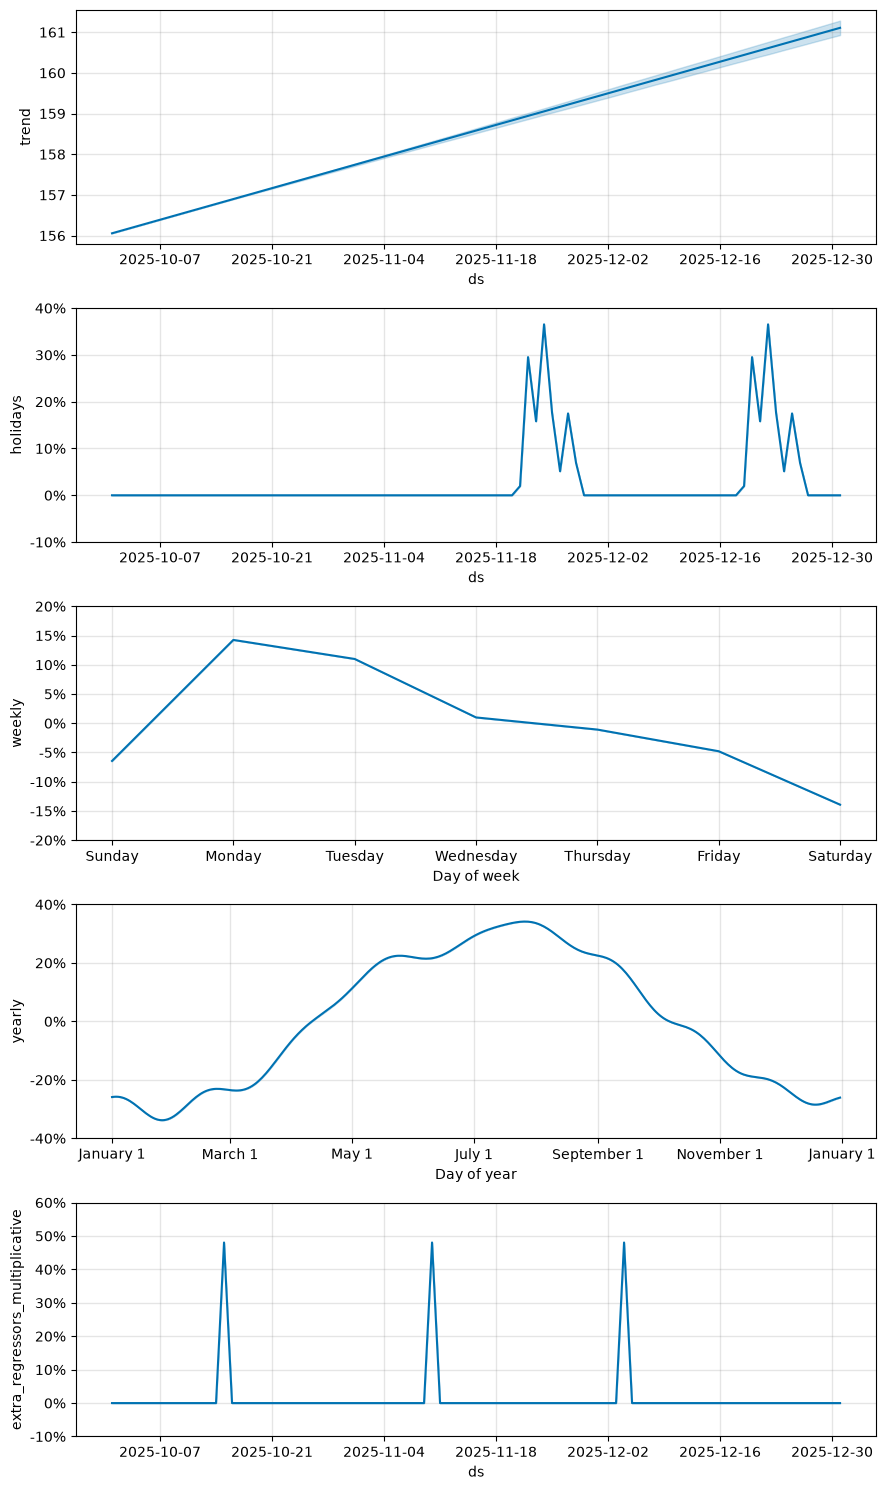

In [6]:
import sys, logging
from prophet import Prophet

logging.getLogger("cmdstanpy").setLevel(logging.WARNING)  # hide Prophet's progress spam
sys.path.insert(0, str(ROOT))
from src.generate_data import HOLIDAYS

holidays_df = pd.DataFrame({
    "holiday": "us_holiday",
    "ds": pd.to_datetime(HOLIDAYS),
    "lower_window": -6,   # the effect starts 6 days before the holiday
    "upper_window": 1,    # and lasts until the day after
})

def prophet_forecast(sku):
    tr = train[train["sku"] == sku].rename(columns={"date": "ds", "units_sold": "y"})
    te = test[test["sku"] == sku].rename(columns={"date": "ds"})
    model = Prophet(seasonality_mode="multiplicative", holidays=holidays_df,
                    yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
    model.add_regressor("on_promo")
    model.fit(tr[["ds", "y", "on_promo"]])
    forecast = model.predict(te[["ds", "on_promo"]])
    return model, forecast

model, fc = prophet_forecast("SKU-001")
actual = test.loc[test["sku"] == "SKU-001", "units_sold"].to_numpy()
print(f"SKU-001 Prophet WAPE: {wape(actual, fc['yhat'].clip(lower=0).to_numpy()):.1f}%")
model.plot_components(fc);

In [7]:
test["prophet"] = 0.0
for sku in test["sku"].unique():
    _, fc = prophet_forecast(sku)
    test.loc[test["sku"] == sku, "prophet"] = fc["yhat"].clip(lower=0).to_numpy()
    print(f"{sku} done")

models = baselines + ["prophet"]
scores = pd.DataFrame({
    "WAPE_%": [wape(test["units_sold"], test[m]) for m in models],
    "bias_%": [bias(test["units_sold"], test[m]) for m in models],
}, index=models).round(1).sort_values("WAPE_%")
scores

12:58:24 - cmdstanpy - INFO - Chain [1] start processing
12:58:24 - cmdstanpy - INFO - Chain [1] done processing
12:58:24 - cmdstanpy - INFO - Chain [1] start processing


SKU-001 done


12:58:24 - cmdstanpy - INFO - Chain [1] done processing
12:58:25 - cmdstanpy - INFO - Chain [1] start processing


SKU-002 done


12:58:25 - cmdstanpy - INFO - Chain [1] done processing
12:58:25 - cmdstanpy - INFO - Chain [1] start processing


SKU-003 done


... (11 outputs left out)

SKU-009 done


12:58:27 - cmdstanpy - INFO - Chain [1] done processing


SKU-010 done


,WAPE_%,bias_%
prophet,20.9,1.8
naive,27.5,-8.0
same_day_last_year,31.3,-4.4
moving_avg_28,31.6,6.4
seasonal_naive_7,37.2,1.5


In [8]:
per_sku = test.groupby("sku").apply(
    lambda g: pd.Series({"avg_daily_units": g["units_sold"].mean(),
                         "prophet_WAPE_%": wape(g["units_sold"], g["prophet"])}),
    include_groups=False,
).round(1)
per_sku.sort_values("avg_daily_units", ascending=False)

,avg_daily_units,prophet_WAPE_%
sku,,
SKU-004,140.6,18.1
SKU-001,139.0,18.0
SKU-002,86.1,20.6
SKU-005,68.7,19.5
SKU-009,52.6,22.8
SKU-006,42.6,24.1
SKU-003,34.3,25.4
SKU-007,33.7,27.7
SKU-008,18.0,29.9


In [9]:
import lightgbm as lgb

holiday_dates = pd.to_datetime(HOLIDAYS)

def days_to_next_holiday(date):
    upcoming = [(h - date).days for h in holiday_dates if h >= date]
    return min(min(upcoming), 30) if upcoming else 30

feat = df.sort_values(["sku", "date"]).reset_index(drop=True)
by_sku = feat.groupby("sku")["units_sold"]

feat["day_of_week"] = feat["date"].dt.day_of_week
feat["day_of_year"] = feat["date"].dt.day_of_year
feat["days_to_holiday"] = feat["date"].map(days_to_next_holiday)
feat["last_year_avg7"] = by_sku.transform(lambda s: s.shift(364).rolling(7, center=True, min_periods=1).mean())
feat["recent_level"] = by_sku.transform(lambda s: s.shift(92).rolling(28, min_periods=1).mean())
feat["sku"] = feat["sku"].astype("category")

FEATURES = ["sku", "day_of_week", "day_of_year", "on_promo", "days_to_holiday",
            "last_year_avg7", "recent_level"]

train_ml = feat[(feat["date"] < TEST_START) & feat["last_year_avg7"].notna()]
test_ml = feat[feat["date"] >= TEST_START]

model = lgb.LGBMRegressor(objective="poisson", n_estimators=500, learning_rate=0.05,
                          random_state=42, verbose=-1)
model.fit(train_ml[FEATURES], train_ml["units_sold"])

preds = pd.Series(model.predict(test_ml[FEATURES]).clip(min=0),
                  index=pd.MultiIndex.from_frame(test_ml[["date", "sku"]].astype({"sku": str})))
test["lightgbm"] = [preds[(d, s)] for d, s in zip(test["date"], test["sku"])]

print(f"Training rows: {len(train_ml):,} (from {train_ml['date'].min().date()})")
print(f"LightGBM WAPE: {wape(test['units_sold'], test['lightgbm']):.1f}%   bias: {bias(test['units_sold'], test['lightgbm']):+.1f}%")

Training rows: 6,430 (from 2023-12-28)
LightGBM WAPE: 22.3%   bias: -2.3%


In [10]:
test["ensemble"] = (test["prophet"] + test["lightgbm"]) / 2

models = baselines + ["prophet", "lightgbm", "ensemble"]
scores = pd.DataFrame({
    "WAPE_%": [wape(test["units_sold"], test[m]) for m in models],
    "bias_%": [bias(test["units_sold"], test[m]) for m in models],
}, index=models).round(1).sort_values("WAPE_%")
print(scores)

# Save forecasts for step 5 (inventory policy)
out = ROOT / "data" / "processed"
out.mkdir(exist_ok=True)
test.to_csv(out / "forecasts.csv", index=False)
scores.to_csv(out / "model_scores.csv")
print(f"\nSaved forecasts to {out / 'forecasts.csv'}")

                    WAPE_%  bias_%
prophet               20.9     1.8
ensemble              21.0    -0.2
lightgbm              22.3    -2.3
naive                 27.5    -8.0
same_day_last_year    31.3    -4.4
moving_avg_28         31.6     6.4
seasonal_naive_7      37.2     1.5

Saved forecasts to c:\Users\iabdu\OneDrive\Desktop\Python-Projects\projects\demand-forecasting-inventory\data\processed\forecasts.csv


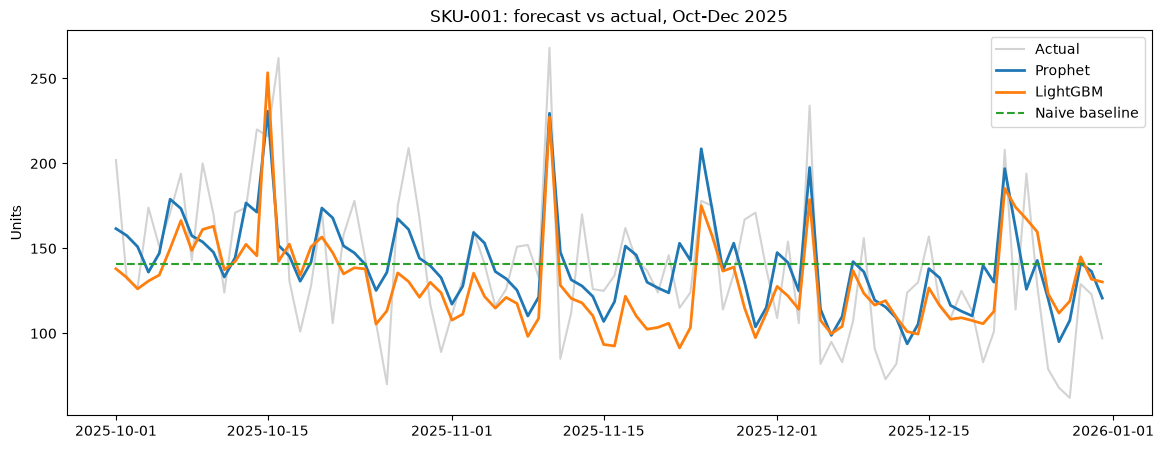

In [11]:
sku = "SKU-001"
s = test[test["sku"] == sku]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(s["date"], s["units_sold"], color="lightgray", label="Actual")
ax.plot(s["date"], s["prophet"], label="Prophet", linewidth=2)
ax.plot(s["date"], s["lightgbm"], label="LightGBM", linewidth=2)
ax.plot(s["date"], s["naive"], label="Naive baseline", linestyle="--")
ax.set_title(f"{sku}: forecast vs actual, Oct-Dec 2025")
ax.set_ylabel("Units")
ax.legend()
plt.show()